# Task 3 — Supervised learning: predicting station availability one hour ahead

By: Haitam LACHGAR, Louis NDJOUNTCHE NJIKI

**Question.** For a given station $s$ at a given hour $t$, how many bikes will be *available to rent* at $t + 1\,\text{h}$?
Operators use this kind of forecast to plan the transfer of bikes from full stations to empty ones.

**Main metric.** MAE (mean absolute error, in bikes), complemented by RMSE, $R^2$ and an operational metric (detection of stations about to be empty).

**Plan of the notebook**

| § | Content |
|---|---|
| 0 | Setup and constants |
| 1 | Understanding `stations_status.csv`: it is a **change log** |
| 2 | Building the learning problem: forecast origins, as-of lookups, features, target |
| 3 | Exploratory analysis of the problem and PCA (diagnostic) |
| 4 | Validation protocol: unseen cities + chronological split |
| 5 | Models, selection, PCA ablation, results on the internal test |
| 6 | Uncertainty (quantile regression) and empty-station alerts |
| 7 | Error analysis and feature importance |
| 8 | Final evaluation on the 2026 evaluation set with the frozen model |
| 9 | Conclusion and limitations |


## 0. Setup

We only use `numpy`, `pandas`, `scikit-learn` and `matplotlib`.

| Constant | Value | Meaning |
|---|---|---|
| `HORIZON` | 3600 s | we predict one hour ahead |
| `STEP` | 3600 s | one forecast per station and per full hour |
| `MAX_STALE_H` | 24 h | if a station has not changed for more than 24 h, we consider it out of service |
| `N_ORIGINS` | 600 000 | maximum number of examples sampled to build the training data |
| `SEED` | 42 | reproducibility (sampling, city split, models) |

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score

warnings.filterwarnings("ignore")

DATA_DIR = Path("data")            # bike_sharing_challenge_2026 files
EVAL_DIR = Path("data")       # "Supervised evaluation dataset 2026"
FILES = dict(
    status="../data/stations_status.csv",
    stations="../data/stations.csv",
    cities="../data/cities.csv",
    status_eval="../data/stations_status_eval.csv",
    stations_eval="../data/stations_eval.csv"
)

SEED = 42             # fixed seed: every random step is reproducible
HORIZON = 3600        # prediction horizon in seconds (1 hour)
STEP = 3600           # spacing between two forecast origins of the same station (1 hour)
MAX_STALE_H = 24      # a state older than 24 h is considered unreliable (station probably off)
N_ORIGINS = 600_000   # maximum number of (station, hour) examples kept for training/validation/test
rng = np.random.default_rng(SEED)

## 1. Understanding `stations_status.csv`

Each row gives the state of one station at one time: bikes present, bikes reserved, bikes available to rent, free docks, maintenance flag.

`load_status` reads the file and adds two columns that we will use everywhere:

* `capacity = bikes + free_racks`: the number of docks of the station (0 for a *virtual* station, i.e. a sign without docks);
* `n_events`: the **cumulative number of rows** of the station (0, 1, 2, ...). Since a row is a change of state (see §1.1), the number of changes between two times is simply a difference:
$$\text{changes in } [t-h,\ t] = N(t) - N(t-h).$$

In [2]:
def load_status(path):
    cols = ["station_id", "time", "bikes", "booked_bikes",
            "bikes_available_to_rent", "free_racks", "maintenance"]
    s = pd.read_csv(path, usecols=cols)
    s["time"] = s["time"].astype("int64")                                 # Unix time in seconds
    s["maintenance"] = s["maintenance"].astype(str).str.lower() == "true" # "True"/"False" -> boolean
    s = s.sort_values(["station_id", "time"])                             # chronological order per station
    s = s.drop_duplicates(["station_id", "time"], keep="last")            # one state per (station, time)
    s["capacity"] = s["bikes"] + s["free_racks"]                          # number of docks
    s["n_events"] = s.groupby("station_id").cumcount()                    # 0, 1, 2, ... per station
    return s.reset_index(drop=True)


status = load_status(FILES["status"])
stations = pd.read_csv(FILES["stations"])

print("rows:", len(status))
print("stations:", status["station_id"].nunique())
print("from", pd.to_datetime(status["time"].min(), unit="s"), "to", pd.to_datetime(status["time"].max(), unit="s"))
status.head()

rows: 2925967
stations: 2899
from 2022-08-26 14:48:01 to 2023-07-15 21:59:01


,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,maintenance,capacity,n_events
0,94,1661778721,5,0,5,0,False,5,0
1,94,1661778781,4,0,4,0,False,4,1
2,94,1661866201,5,0,5,0,False,5,2
3,94,1661968621,4,0,4,0,False,4,3
4,94,1661969101,5,0,5,0,False,5,4


### 1.1 Snapshot or change log?

Before building anything we must know **what one row means**. Two possibilities:

1. a *snapshot* taken at regular intervals (e.g. every 5 minutes);
2. a *change log*: a row is written only when the state of the station changes.

We test it with two simple statistics: the share of rows identical to the previous row of the same station (a snapshot would contain many, because most of the time nothing changes), and the distribution of the gaps between rows (a snapshot would have constant gaps).

rows identical to the previous one: 2.95 %
median gap (min): 28
90% of gaps below (h): 12.0
99% of gaps below (h): 78.4


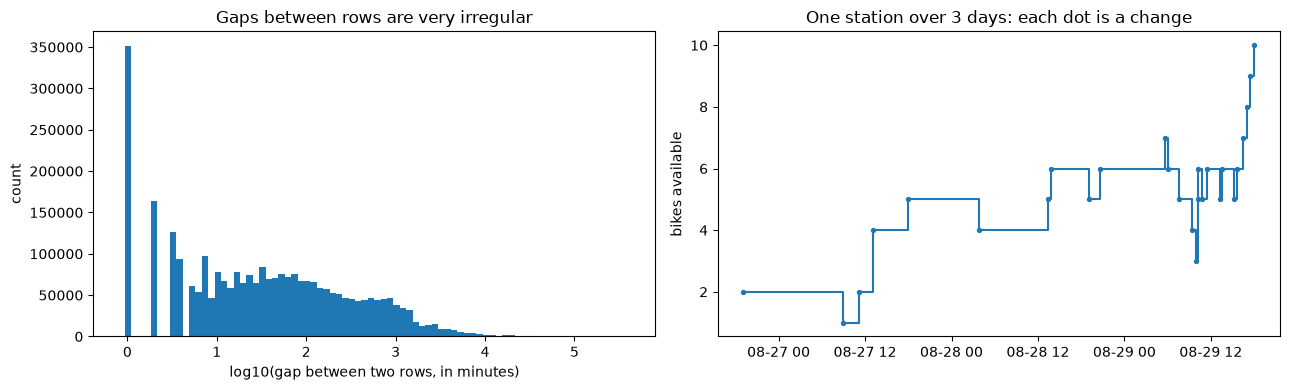

In [3]:
cols = ["bikes", "booked_bikes", "bikes_available_to_rent", "free_racks", "maintenance"]
previous = status.groupby("station_id")[cols].shift()        # previous row of the same station
same_as_previous = (previous == status[cols]).all(axis=1)    # True if nothing changed
gap_h = status.groupby("station_id")["time"].diff() / 3600   # hours since the previous row

print("rows identical to the previous one:", round(same_as_previous.mean() * 100, 2), "%")
print("median gap (min):", round(gap_h.median() * 60))
print("90% of gaps below (h):", round(gap_h.quantile(0.90), 1))
print("99% of gaps below (h):", round(gap_h.quantile(0.99), 1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].hist(np.log10(gap_h.dropna() * 60), bins=80)           # log scale: gaps go from seconds to days
ax[0].set_xlabel("log10(gap between two rows, in minutes)")
ax[0].set_ylabel("count")
ax[0].set_title("Gaps between rows are very irregular")

one_station = status["station_id"].value_counts().index[100]
ex = status[status["station_id"] == one_station]
ex = ex[ex["time"] < ex["time"].min() + 3 * 86400]           # first 3 days of this station
ex_time = pd.to_datetime(ex["time"], unit="s")
ax[1].step(ex_time, ex["bikes_available_to_rent"], where="post")   # value holds until the next row
ax[1].scatter(ex_time, ex["bikes_available_to_rent"], s=8)
ax[1].set_ylabel("bikes available")
ax[1].set_title("One station over 3 days: each dot is a change")

plt.tight_layout()
plt.show()

**Result.** Only about 2.9 % of rows repeat the previous state, and the gaps are very irregular (median ≈ 28 min, but 10 % of gaps are longer than 12 h and 1 % longer than 78 h). The file is therefore a **change log**: a row is written when the state changes, and **the state stays valid until the next row**.

**Consequence.** The availability of station $s$ at *any* time $\tau$ is the value of the last row before $\tau$ (an *as-of* value):
$$A_s(\tau) = \text{avail}_s\big(\max\{t_i \le \tau\}\big).$$

For instance, a naive approach would look for a row "around $t+1$ h ± 10 min". With a change log this is wrong: during quiet periods (nights, small stations) there is often no row in that window, so the example would be dropped, although we know the exact value (nothing changed). Training would then be biased towards busy moments. We use the exact as-of lookup instead (§2.2).

**Out-of-service stations.** A change log cannot distinguish "nothing happened" from "the station stopped sending data". We therefore keep a state only if it is at most `MAX_STALE_H = 24 h` old, and we discard stations under maintenance.

## 2. Building the learning problem

The raw data is an irregular log, but a supervised model needs a table where **one row = one example** $(X, y)$. We build it in three steps:

```
  make_origins          asof                       build_dataset
  ─────────────         ─────────────────          ──────────────────────────────
  choose WHEN we        read the state of a        combine the lookups into
  make a prediction  →  station at ANY time     →  27 features X and the target y
  (station, hour t)     (past, now, future)        + remove invalid examples
```

### 2.0 Local time zones

People commute at 8 a.m. **local time**. Raw times are in UTC, so we convert them to the time zone of each city (with daylight saving time). The time zone is derived from the country column of `cities.csv`; Central European Time (Europe/Berlin) is the default.

In [4]:
TZ = {"GB": "Europe/London", "UK": "Europe/London", "UNITED KINGDOM": "Europe/London",
      "IE": "Europe/Dublin", "IRELAND": "Europe/Dublin",
      "PT": "Europe/Lisbon", "PORTUGAL": "Europe/Lisbon",
      "FI": "Europe/Helsinki", "FINLAND": "Europe/Helsinki",
      "EE": "Europe/Tallinn", "LV": "Europe/Riga", "LT": "Europe/Vilnius",
      "GR": "Europe/Athens", "BG": "Europe/Sofia", "RO": "Europe/Bucharest",
      "CY": "Asia/Nicosia", "TR": "Europe/Istanbul", "UA": "Europe/Kyiv"}


def city_timezones(path):
    cities = pd.read_csv(path)
    country_col = [c for c in cities.columns if "country" in c.lower()][0]   # find the country column
    id_col = "id" if "id" in cities.columns else "city_id"
    country = cities[country_col].astype(str).str.upper().str.strip()
    zone = country.map(TZ).fillna("Europe/Berlin")                            # default: CET
    return dict(zip(cities[id_col], zone))                                    # city_id -> time zone


tz_map = city_timezones(FILES["cities"])
print(pd.Series(tz_map).value_counts())

Europe/Berlin    255
Europe/London      9
Asia/Nicosia       2
Europe/Riga        1
Name: count, dtype: int64


### 2.1 Forecast origins: `make_origins`

A **forecast origin** is a pair (station $s$, time $t$): the moment when an operator asks *"how many bikes will be here in one hour?"*. Each origin becomes one row of the final table.

For each station we create one origin **every full hour**:

* the first origin is the first full hour **after** the first row of the station (before it, the state is unknown);
* the last origin is the last full hour such that $t + 1$ h is still before the last row (otherwise we could not know the target).

Example with station 7, whose first row is at 08:12 and last row at 12:40:

```
 08:12 (first row)                                         12:40 (last row)
   │      09:00        10:00        11:00        12:00        │
   │        ●────────────●────────────●            ✗           │
   │      start                     last origin   target 13:00 would be
   │                                (11:00 + 1 h = 12:00 ≤ 12:40)   after the last row
```

$\text{start} = (\lfloor t_{\min} / 3600 \rfloor + 1) \times 3600$ and the origins are $\text{start}, \text{start} + 1\text{h}, \dots$ up to $t_{\max} - 1\text{h}$.

For training we randomly sample `n` origins (several millions exist); for the final evaluation we keep all of them (`n=None`).

In [5]:
def make_origins(status, n=None):
    parts = []
    for station_id, g in status.groupby("station_id"):
        start = (g["time"].min() // STEP + 1) * STEP     # first full hour after the first row
        last = g["time"].max() - HORIZON                 # the target t + 1 h must exist
        times = np.arange(start, last + 1, STEP)         # one origin per hour
        parts.append(pd.DataFrame({"station_id": station_id, "time": times}))
    origins = pd.concat(parts, ignore_index=True)

    if n is not None and n < len(origins):
        origins = origins.sample(n, random_state=SEED)   # random subset for training
    return origins

### 2.2 Reading the state at any time: `asof`

`asof(origins, log, offset, cols)` answers, **for all origins at once**, the question *"what was the state of the station at time $t + \text{offset}$?"*:

* `offset = 0` → the current state;
* `offset = -3600` → the state one hour ago (a lag, used for features);
* `offset = +3600` → the state in one hour (**the target**).

It relies on `pandas.merge_asof` with `direction="backward"` (take the last row whose time is $\le t + \text{offset}$) and `by="station_id"` (only rows of the same station). If there is no row before that time, the result is `NaN`. The function also returns `age_h`, the age of the row that was found.

`merge_asof` requires both tables to be sorted by time, which mixes the origins. We keep the original row number in a column and restore the order at the end, so that the results of different calls can be combined row by row.

```
 station 7:   08:12 (5)   08:47 (4)   09:05 (2)   09:58 (3)          11:30 (6)
 ──────────────●───────────●───────────●───────────●─────────────────────●──────▶
                                 ▲ t = 09:00                ▲ t + 1 h = 10:00
               last row ≤ 09:00 = 08:47 → A(t) = 4         last row ≤ 10:00 = 09:58 → y = 3
```

In [6]:
def asof(origins, status_by_time, offset, cols):
    query = origins[["station_id", "time"]].copy()
    query["t_q"] = query["time"] + offset                 # the time we ask about
    query = query.reset_index().sort_values("t_q")        # keep the original row number, sort by time

    log = status_by_time[["station_id", "time"] + cols].rename(columns={"time": "t_ev"})

    result = pd.merge_asof(query, log, left_on="t_q", right_on="t_ev",
                           by="station_id", direction="backward")   # last row of the same station <= t_q
    result["age_h"] = (result["t_q"] - result["t_ev"]) / 3600       # how old the information is

    result = result.set_index("index")
    return result.loc[origins.index]                      # same order as the input origins

### 2.3 Features and target: `build_dataset`

`build_dataset` calls `asof` about 20 times (now, in one hour, and at 18 past times) and combines the results into **27 features** and the target.

```
origin (station 7, Monday 08:00)
        │
        ├── asof(t + 1 h)                          → y = 9          ← the target
        ├── asof(t)                                → 12 bikes now
        ├── asof(t − 15 min, −30 min, −1 h, −3 h, −24 h)  → recent past
        └── asof(t − 24k h and t − 24k h + 1 h), k = 1..7 → same hour on the 7 previous days
```

Two rules make the table honest:

* **no information after $t$ in $X$**: only the target looks at $t + 1$ h (otherwise the model would "cheat", i.e. data leakage);
* **no identifier in $X$**: no station id, city id or coordinates. The evaluation set contains **new cities**, so the model must learn general behaviours ("a station that empties every morning and is fuller than usual will empty"), not station-specific facts.

**The 27 features, by family** ($A_h = A(t-h)$ bikes available, $N_h = N(t-h)$ event counter):

| Family | Features | Formula / meaning |
|---|---|---|
| Current state (6) | `avail`, `booked`, `free_racks`, `capacity`, `occupancy`, `hours_since_change` | starting point; `occupancy` $= A_0 / \max(\text{capacity}, \max_k A_{24k}, 1)$ |
| Trend (4) | `d_15m`, `d_30m`, `d_1h`, `d_3h` | $A_0 - A_h$: is the station emptying or filling right now? |
| Activity (4) | `events_0.25h`, `events_1h`, `events_3h`, `events_24h` | $N_0 - N_h$: number of changes, i.e. how busy the station is |
| Seasonality (7) | `yday_next` $= A_{23} - A_{24}$, `lastweek_next` $= A_{167} - A_{168}$, `week_next`, `week_abs_next`, `week_events_next`, `week_level`, `dev_from_level` | what this station usually does during the **next hour**, computed from its own last 7 days |
| Station type (1) | `virtual` | station without docks |
| Calendar (5) | `hour`, `dow`, `weekend`, `hour_sin`, `hour_cos` | local time; sin/cos put the hour on a circle so that 23 h and 0 h are neighbours |

With $\delta_k = A(t-24k+1\text{h}) - A(t-24k)$ the change during "the next hour" $k$ days ago:
$$\texttt{week\_next} = \tfrac17\sum_{k=1}^{7}\delta_k,\quad \texttt{week\_abs\_next} = \tfrac17\sum_{k}|\delta_k|,\quad \texttt{week\_level} = \tfrac17\sum_k A_{24k},\quad \texttt{dev\_from\_level} = A_0 - \texttt{week\_level}.$$

The seasonal family is the key idea: it is a **station-specific profile computed on the fly from the station's own past**, so it exists for a station the model has never seen, without retraining.

**Missing values.** When the history of a station is too short (e.g. its first day), some lookups find no row and the feature is `NaN`. We keep these `NaN`:

* the weekly means ignore missing days (a station with 3 days of history gets a mean over 3 days);
* replacing by 0 would be wrong, because 0 is a real value ("no change");
* dropping the rows would make it impossible to predict for recent stations, i.e. for new cities;
* `HistGradientBoosting` handles `NaN` natively (it learns on which side of each split to send them); for Ridge and PCA we impute the training median inside a pipeline.

**Target.** $y = A(t+1\text{h})$, read by `asof(t + 1 h)`.

**Validity filter.** An origin is kept only if the state at $t$ and the state at $t + 1$ h are at most 24 h old and the station is not under maintenance at $t$.

In [7]:
def build_dataset(origins, status, stations, tz_map):
    st = status.sort_values("time")                 # sorted once, reused by every asof call
    cols = ["bikes_available_to_rent", "n_events"]

    # ---- as-of lookups ---------------------------------------------------------------
    now = asof(origins, st, 0, cols + ["booked_bikes", "free_racks", "capacity", "maintenance"])
    fut = asof(origins, st, HORIZON, cols)          # state at t + 1 h -> target

    lags = [0.25, 0.5, 1, 3, 23, 24]                # recent past (hours) + yesterday
    for k in range(2, 8):
        lags += [24 * k - 1, 24 * k]                # same hour (and one hour later) k days ago
    past = {h: asof(origins, st, -int(h * 3600), cols) for h in lags}

    A0 = now["bikes_available_to_rent"]             # bikes available at t
    N0 = now["n_events"]                            # event counter at t
    A = {h: past[h]["bikes_available_to_rent"] for h in lags}   # A[h] = A(t - h)
    N = {h: past[h]["n_events"] for h in lags}                  # N[h] = N(t - h)
    days = range(1, 8)

    X = pd.DataFrame(index=origins.index)

    # ---- current state ---------------------------------------------------------------
    X["avail"] = A0
    X["booked"] = now["booked_bikes"]
    X["free_racks"] = now["free_racks"]
    X["capacity"] = now["capacity"]
    X["hours_since_change"] = now["age_h"]

    # ---- recent trend: A(t) - A(t - h) -------------------------------------------------
    X["d_15m"] = A0 - A[0.25]
    X["d_30m"] = A0 - A[0.5]
    X["d_1h"] = A0 - A[1]
    X["d_3h"] = A0 - A[3]

    # ---- activity: number of changes in the window ------------------------------------
    X["events_0.25h"] = N0 - N[0.25]
    X["events_1h"] = N0 - N[1]
    X["events_3h"] = N0 - N[3]
    X["events_24h"] = N0 - N[24]

    # ---- seasonality: what happened during the next hour on the 7 previous days -------
    next_hour_change = pd.concat([A[24 * k - 1] - A[24 * k] for k in days], axis=1)   # 7 columns
    level_same_hour = pd.concat([A[24 * k] for k in days], axis=1)
    next_hour_events = pd.concat([N[24 * k - 1] - N[24 * k] for k in days], axis=1)

    X["yday_next"] = A[23] - A[24]
    X["lastweek_next"] = A[167] - A[168]
    X["week_next"] = next_hour_change.mean(axis=1)            # mean ignores missing days
    X["week_level"] = level_same_hour.mean(axis=1)
    X["dev_from_level"] = A0 - X["week_level"]
    X["week_abs_next"] = next_hour_change.abs().mean(axis=1)
    X["week_events_next"] = next_hour_events.mean(axis=1)

    # ---- occupancy (virtual stations have capacity 0 -> use the weekly maximum) -------
    week_max = pd.concat([level_same_hour, A0], axis=1).max(axis=1)
    denominator = np.maximum(np.maximum(X["capacity"], week_max), 1)
    X["occupancy"] = A0 / denominator

    # ---- station type -------------------------------------------------------------------
    station_info = stations.set_index("id")
    city = origins["station_id"].map(station_info["city_id"])
    racks = origins["station_id"].map(station_info["bike_racks"]).fillna(0)
    X["virtual"] = (racks == 0).astype(int)

    # ---- calendar in local time ---------------------------------------------------------
    zone = city.map(tz_map).fillna("Europe/Berlin")
    utc = pd.to_datetime(origins["time"], unit="s", utc=True)
    hour = pd.Series(np.nan, index=origins.index)
    dow = pd.Series(np.nan, index=origins.index)
    for z in zone.unique():                         # convert each time zone separately
        mask = zone == z
        local = utc[mask].dt.tz_convert(z)
        hour[mask] = local.dt.hour
        dow[mask] = local.dt.dayofweek              # 0 = Monday ... 6 = Sunday
    X["hour"] = hour
    X["dow"] = dow
    X["weekend"] = (dow >= 5).astype(int)
    X["hour_sin"] = np.sin(2 * np.pi * hour / 24)   # hour on a circle
    X["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    # ---- validity filter ------------------------------------------------------------------
    valid = (now["age_h"] <= MAX_STALE_H) & (fut["age_h"] <= MAX_STALE_H)
    valid = valid & ~now["maintenance"].astype(bool)

    # ---- meta: NOT features, only used for splitting and analysis -------------------
    meta = origins.copy()
    meta["city_id"] = city.fillna(-1).astype(int)
    meta["y"] = fut["bikes_available_to_rent"]

    return X[valid].astype("float32"), meta.loc[valid, "y"].astype("float32"), meta[valid]

### 2.4 Worked example on a tiny synthetic station

To check that the three functions do what we expect, we run them on a small hand-made log before using the real data. Station 7 has 15 docks. On each of the 7 previous days it goes from 10 to 7 bikes between 08:00 and 09:00 (people leaving for work). On Monday 13 March it is fuller than usual (12 bikes at 08:00). We ask for the forecast made on Monday at 08:00.

(These variables are prefixed `toy_` and are not used anywhere else.)

In [8]:
import io

def to_unix(s):                                      # "2023-03-13 08:00" (Berlin time) -> seconds
    return int(pd.Timestamp(s, tz="Europe/Berlin").timestamp())

toy_rows = []
for d in range(6, 14):
    day = f"2023-03-{d:02d}"
    if d < 13:                                       # 7 "usual" days
        toy_rows += [(day + " 07:30", 10), (day + " 08:20", 8), (day + " 08:45", 7), (day + " 18:10", 10)]
    else:                                            # Monday 13: fuller than usual
        toy_rows += [(day + " 07:30", 12), (day + " 07:40", 11), (day + " 07:55", 12),
                     (day + " 08:20", 10), (day + " 08:50", 9), (day + " 10:30", 11)]

toy_csv = "station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,maintenance\n"
toy_csv += "\n".join(f"7,{to_unix(t)},{b},0,{b},{15 - b},False" for t, b in toy_rows)
toy_status = load_status(io.StringIO(toy_csv))
toy_stations = pd.DataFrame({"id": [7], "city_id": [1], "bike_racks": [15]})

toy_origins = make_origins(toy_status)
print("number of hourly origins for this station:", len(toy_origins))

toy_one = pd.DataFrame({"station_id": [7], "time": [to_unix("2023-03-13 08:00")]})
toy_X, toy_y, toy_meta = build_dataset(toy_one, toy_status, toy_stations, {1: "Europe/Berlin"})
print("target y = A(t + 1h) =", toy_y.iloc[0], "| current availability =", toy_X["avail"].iloc[0])
toy_X.T.rename(columns={0: "value"}).round(3)

number of hourly origins for this station: 170
target y = A(t + 1h) = 9.0 | current availability = 12.0


,value
avail,12.000
booked,0.000
free_racks,3.000
capacity,15.000
hours_since_change,0.083
d_15m,1.000
d_30m,0.000
d_1h,2.000
d_3h,2.000
events_0.25h,1.000


**Reading the example.**

* Current state: 12 bikes, 3 free docks, capacity 15, occupancy 12/15 = 0.8; the last change was 5 minutes ago (`hours_since_change` ≈ 0.08).
* Trend: `d_1h` = +2 (10 bikes at 07:00, 12 now).
* Activity: 3 changes in the last hour (07:30, 07:40, 07:55).
* Seasonality: every day, the station lost 3 bikes between 08:00 and 09:00, so `yday_next` = `lastweek_next` = `week_next` = −3, with 2 changes in that hour (`week_events_next` = 2). The usual level at 08:00 is 10, so `dev_from_level` = +2 (fuller than usual).
* Calendar: Monday (`dow` = 0), 8 a.m.

All signals point to a decrease, and the true target is 9 bikes (Δ = −3). Persistence would have predicted 12.

### 2.5 Building the real dataset

We sample 1.5 × `N_ORIGINS` origins, because some of them will be removed by the validity filter, then keep at most `N_ORIGINS` valid ones. Since the origins are sampled at random, the first valid ones are still a random sample. `FEATURES` stores the list and the order of the columns; the frozen model will receive exactly these columns at evaluation time.

In [9]:
t0 = time.time()
origins = make_origins(status, n=int(N_ORIGINS * 1.5))   # oversample: about half will be invalid
X, y, meta = build_dataset(origins, status, stations, tz_map)

X = X.iloc[:N_ORIGINS]
y = y.iloc[:N_ORIGINS]
meta = meta.iloc[:N_ORIGINS]
FEATURES = list(X.columns)

print("valid origins:", len(X))
print("features:", len(FEATURES))
print("stations:", meta["station_id"].nunique(), "| cities:", meta["city_id"].nunique())
print("time (s):", round(time.time() - t0))
X.describe().T.round(2)

valid origins: 459643
features: 27
stations: 2797 | cities: 182
time (s): 8


,count,mean,std,min,25%,50%,75%,max
avail,459643.0,4.82,4.52,0.00,2.00,4.00,7.00,166.00
booked,459643.0,0.00,0.07,-1.00,0.00,0.00,0.00,20.00
free_racks,459643.0,3.16,4.21,0.00,0.00,1.00,5.00,69.00
capacity,459643.0,7.98,6.21,0.00,4.00,7.00,12.00,166.00
hours_since_change,459643.0,7.27,6.29,0.02,1.85,5.52,11.55,24.00
d_15m,459597.0,0.00,0.35,-21.00,0.00,0.00,0.00,12.00
d_30m,459558.0,0.00,0.49,-40.00,0.00,0.00,0.00,15.00
d_1h,459502.0,-0.00,0.70,-45.00,0.00,0.00,0.00,18.00
d_3h,459227.0,-0.00,1.19,-46.00,0.00,0.00,0.00,92.00
events_0.25h,459597.0,0.08,0.38,0.00,0.00,0.00,0.00,10.00


**Result.** We obtain 459 643 valid origins (2 797 stations, 182 cities, 27 features): about half of the sampled origins were removed, mostly because the station had not changed for more than 24 h. The `count` column shows the missing values: about 0.7 % for the features that need 24 h of history and 3.7 % for `lastweek_next` (7 days of history). About 40 % of the origins belong to virtual stations.

## 3. Exploratory analysis of the prediction problem

We look at the change $\Delta = A(t+1\text{h}) - A(t)$ to understand how hard the problem is, when changes happen, and which features are linked to them.

share of origins with no change in 1h: 87.0 %
share with |delta| >= 3: 1.3 %


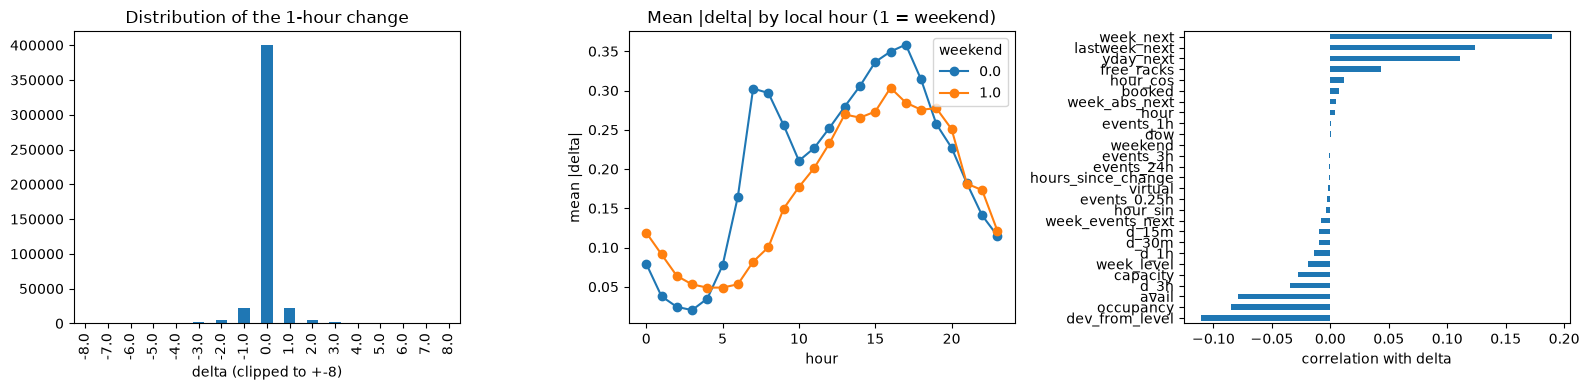

In [10]:
delta = y - X["avail"]
print("share of origins with no change in 1h:", round((delta == 0).mean() * 100, 1), "%")
print("share with |delta| >= 3:", round((delta.abs() >= 3).mean() * 100, 1), "%")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

delta.clip(-8, 8).value_counts().sort_index().plot.bar(ax=ax[0])
ax[0].set_xlabel("delta (clipped to +-8)")
ax[0].set_title("Distribution of the 1-hour change")

by_hour = pd.DataFrame({"hour": X["hour"], "abs_delta": delta.abs(), "weekend": X["weekend"]})
by_hour.groupby(["hour", "weekend"])["abs_delta"].mean().unstack().plot(ax=ax[1], marker="o")
ax[1].set_ylabel("mean |delta|")
ax[1].set_title("Mean |delta| by local hour (1 = weekend)")

corr = X.assign(delta=delta).corr()["delta"].drop("delta").sort_values()
corr.plot.barh(ax=ax[2])
ax[2].set_xlabel("correlation with delta")

plt.tight_layout()
plt.show()

**Analysis.**

* **The problem is dominated by "no change"**: $\Delta = 0$ for 87 % of the origins, and $|\Delta| \ge 3$ for only 1.3 %. The persistence forecast $\hat y = A(t)$ is therefore a very strong reference, and the cases that matter for rebalancing are rare.
* **Daily cycle**: on weekdays, $|\Delta|$ peaks around 8 a.m. and 5 p.m. (commuting) and is close to zero at night; weekends have a flatter afternoon profile. This justifies the calendar features in local time.
* **Correlations** are positive for the seasonal features (`week_next` ≈ +0.19, then `lastweek_next` and `yday_next`): a station tends to do what it usually does at this hour. They are negative for `dev_from_level`, `occupancy` and `avail`: a station that holds more bikes than usual tends to lose some (users find bikes there easily, operators rebalance).
* All correlations stay small (≤ 0.2): the link between features and $\Delta$ is weak and **conditional** (it depends on the hour, the station type, the current level). This motivates non-linear models such as gradient-boosted trees.

### 3.1 PCA as a diagnostic

We run a principal component analysis on the standardised features $Z$ (each column centred and scaled to variance 1, missing values replaced by the median).

PCA looks for orthogonal directions of maximal variance:

The **correlation circle** shows, for each feature $j$, its correlation with PC1 and PC2: $\operatorname{corr}(z_j, PC_k) = w_{kj}\sqrt{\lambda_k}$. Arrows pointing in the same direction are redundant features, opposite arrows are anti-correlated, short arrows are poorly represented in the plane.

We use PCA to see whether some features are redundant and how the information is organised.

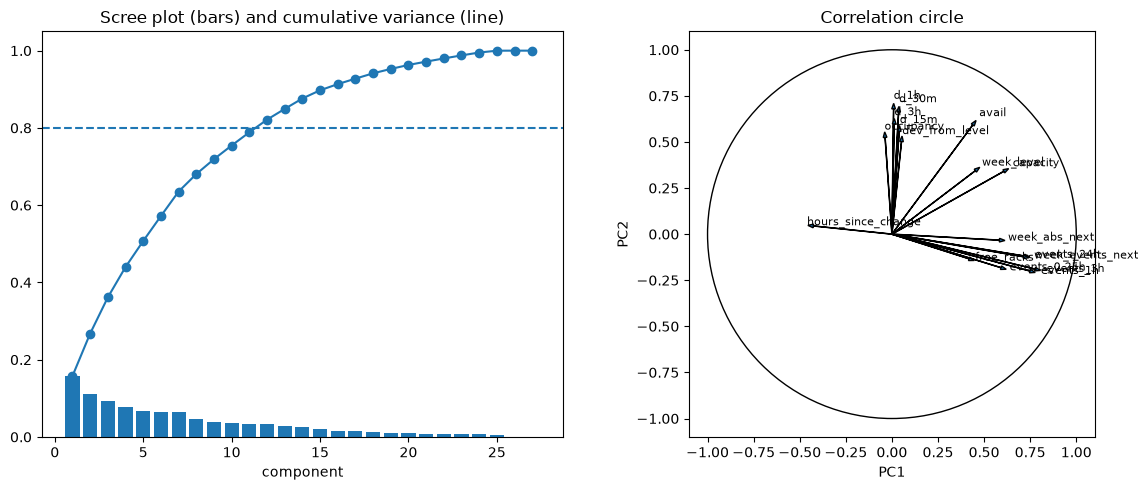

components for 80% of variance: 12
PC1 : ['events_3h', 'events_1h', 'events_24h', 'week_events_next']
PC2 : ['d_1h', 'd_30m', 'd_3h', 'avail']
PC3 : ['capacity', 'week_level', 'avail', 'virtual']


In [11]:
sample = X.sample(min(30_000, len(X)), random_state=SEED)
prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
Z = prep.fit_transform(sample)                     # standardised features

pca = PCA().fit(Z)
ratio = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_[:3].T * np.sqrt(pca.explained_variance_[:3]),
                        index=FEATURES, columns=["PC1", "PC2", "PC3"])   # corr(feature, PC)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].bar(range(1, len(ratio) + 1), ratio)
ax[0].plot(range(1, len(ratio) + 1), np.cumsum(ratio), "o-")
ax[0].axhline(0.8, ls="--")
ax[0].set_xlabel("component")
ax[0].set_title("Scree plot (bars) and cumulative variance (line)")

ax[1].add_patch(plt.Circle((0, 0), 1, fill=False))
for name in FEATURES:
    a, b = loadings.loc[name, "PC1"], loadings.loc[name, "PC2"]
    if a ** 2 + b ** 2 > 0.15:                     # only well-represented features
        ax[1].arrow(0, 0, a, b, head_width=0.02)
        ax[1].text(a * 1.08, b * 1.08, name, fontsize=8)
ax[1].set_xlim(-1.1, 1.1)
ax[1].set_ylim(-1.1, 1.1)
ax[1].set_aspect("equal")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")
ax[1].set_title("Correlation circle")

plt.tight_layout()
plt.show()

print("components for 80% of variance:", int(np.searchsorted(np.cumsum(ratio), 0.8) + 1))
for name in ["PC1", "PC2", "PC3"]:
    top = loadings[name].abs().sort_values(ascending=False).index[:4]
    print(name, ":", list(top))

**Analysis.**

* The variance is spread over many components: 12 components out of 27 are needed for 80 %, and the scree plot has no clear elbow.
* The first axes are **interpretable blocks**: PC1 is an *activity* axis (all `events_*` and `week_events_next`), PC2 a *short-term dynamics* axis (the `d_*` trends with the current stock), PC3 a *station size* axis (capacity, usual level, current stock, opposed to `virtual`). Features inside a block are redundant. This does not harm trees, but it would make the coefficients of a linear model unstable.
**Decision.** PCA is used as a diagnostic. Whether the models should be trained on the components instead of the original features is checked experimentally in §5.2.

## 4. Validation protocol

A random K-fold split would be **wrong** here: two consecutive hours of the same station are almost identical, so a random split would put 8 a.m. in training and 9 a.m. in the test set. The model would be evaluated on the "future" it has almost seen (temporal leakage) and the score would be too optimistic.

The final evaluation uses **new cities**, so we reproduce this situation internally:

* **City hold-out**: 20 % of the cities are removed from training *and* validation.
* **Chronological split**: train = first 70 % of the period, validation = 70–85 % (used to choose the model and the thresholds), test = last 15 %. A one-day gap separates the blocks.
* Rows of the held-out cities **before** the test period are not used at all (`unused`), so these cities stay truly unseen.

```
 time ──────────────────────────────────────────────────────────────────────────▶
 seen cities     │ ███████ train ███████ │gap│ ██ val ██ │gap│ ███ test ███ │
 unseen cities   │ ············· unused ·············        │ ███ test ███ │
                                         70 %            85 %
```

In [12]:
cities = np.sort(meta["city_id"].unique())
n_test_cities = max(1, round(0.2 * len(cities)))
test_cities = rng.choice(cities, size=n_test_cities, replace=False)   # 20 % of cities held out
unseen = meta["city_id"].isin(test_cities)

t1, t2 = np.quantile(meta["time"], [0.70, 0.85])                      # time boundaries
one_day = 86400

split = pd.Series("unused", index=meta.index)
split[(meta["time"] < t1) & ~unseen] = "train"
split[(meta["time"] >= t1 + one_day) & (meta["time"] < t2) & ~unseen] = "val"
split[meta["time"] >= t2 + one_day] = "test"

tr = (split == "train").values
va = (split == "val").values
te = (split == "test").values

print(pd.crosstab(split, unseen.map({False: "seen cities", True: "unseen cities"})))
print("train ends:", pd.to_datetime(t1, unit="s").date())
print("test starts:", pd.to_datetime(t2 + one_day, unit="s").date())

city_id  seen cities  unseen cities
row_0                              
test           55793          11320
train         262609              0
unused          2921          70819
val            56181              0
train ends: 2023-04-21
test starts: 2023-06-11


**Result.** About 272 k training origins, 58 k validation origins and 67 k test origins (58 k from seen cities, 9 k from unseen cities). The internal test on unseen cities in a future period is our closest proxy for the professors' final evaluation.

## 5. Models

We compare models from the simplest to the most flexible:

1. **Persistence** $\hat y = A(t)$: "nothing changes".
2. **Seasonal persistence** $\hat y = A(t) + \texttt{week\_next}$: "the station does what it usually does at this hour". No learning.
3. **Ridge regression** on $\Delta$: a linear model with an $L_2$ penalty, $\min_\beta \|\Delta - Z\beta\|^2 + \alpha\|\beta\|^2$ ($\alpha = 1$), after median imputation and standardisation.
4. **HistGradientBoosting** (HGB): boosted regression trees, $F_m = F_{m-1} + \eta\,h_m$ where each tree $h_m$ fits the negative gradient of the loss. Features are binned into histograms (fast), and missing values are handled natively. We try 8 variants: target = level $y$ or change $\Delta$, loss = squared or absolute, 31 or 127 leaves (31 is the default value, 127 is the maximum value for HistGradientBoostingRegressor). Early stopping uses 10 % of the training data.

**Target.** When we predict $\Delta$, the forecast is $\hat y = \text{clip}(A(t) + \hat\Delta,\ 0,\ \text{capacity})$: never negative, never above the number of docks (no upper bound for virtual stations).

**Metrics.** MAE $= \frac1n\sum|y-\hat y|$ (main, in bikes), RMSE $= \sqrt{\frac1n\sum(y-\hat y)^2}$ (penalises large errors), $R^2$, and `within_1`, the share of rounded predictions within ±1 bike.

In [13]:
def upper_bound(Xp):
    return np.where(Xp["capacity"] > 0, Xp["capacity"], np.inf)   # no bound for virtual stations


def to_level(Xp, delta_pred):
    return np.clip(Xp["avail"].values + delta_pred, 0, upper_bound(Xp))   # A(t) + predicted change


def scores(y_true, y_pred, name):
    return {"model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R2": r2_score(y_true, y_pred),
            "within_1": np.mean(np.abs(y_true - np.round(y_pred)) <= 1)}


def persistence(Xp):
    return Xp["avail"].values


def seasonal_persistence(Xp):
    return to_level(Xp, Xp["week_next"].fillna(0).values)   # no history -> fall back to persistence


baselines = {"Persistence": persistence, "Seasonal persistence": seasonal_persistence}

Xtr, Xva, Xte = X[tr], X[va], X[te]
ytr, yva, yte = y[tr].values, y[va].values, y[te].values
dtr = ytr - Xtr["avail"].values                              # training target for "delta" models

In [14]:
val_results = []
for name, f in baselines.items():
    val_results.append(scores(yva, f(Xva), name))

ridge = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0))
ridge.fit(Xtr, dtr)
val_results.append(scores(yva, to_level(Xva, ridge.predict(Xva)), "Ridge on delta"))

candidates = {}
for target in ["level", "delta"]:
    for loss in ["squared_error", "absolute_error"]:
        for leaves in [31, 127]:  # number of leaves in the trees : 31 is the default value, 127 is the maximum value for HistGradientBoostingRegressor (four times the default complexity)
            model = HistGradientBoostingRegressor(loss=loss, max_leaf_nodes=leaves, learning_rate=0.1,
                                                  max_iter=400, l2_regularization=1.0,
                                                  early_stopping=True, random_state=SEED)
            if target == "level":
                model.fit(Xtr, ytr)
                pred = np.clip(model.predict(Xva), 0, upper_bound(Xva))
            else:
                model.fit(Xtr, dtr)
                pred = to_level(Xva, model.predict(Xva))
            name = f"HGB {target} | {loss} | {leaves} leaves"
            candidates[name] = (model, target)
            val_results.append(scores(yva, pred, name))

val_table = pd.DataFrame(val_results).set_index("model").sort_values("MAE")
val_table.round(3)

,MAE,RMSE,R2,within_1
model,,,,
HGB delta | absolute_error | 31 leaves,0.234,0.747,0.969,0.953
HGB delta | absolute_error | 127 leaves,0.235,0.742,0.969,0.953
Persistence,0.235,0.750,0.969,0.953
HGB delta | squared_error | 127 leaves,0.266,0.728,0.970,0.954
HGB delta | squared_error | 31 leaves,0.266,0.725,0.971,0.954
HGB level | squared_error | 31 leaves,0.271,0.726,0.971,0.954
HGB level | squared_error | 127 leaves,0.273,0.728,0.970,0.953
Ridge on delta,0.285,0.734,0.970,0.953
HGB level | absolute_error | 31 leaves,0.288,1.019,0.942,0.950


### 5.1 Model selection

We select on the **validation MAE** (our main metric). We also keep, as a **secondary model declared here, before any evaluation**, the squared-loss HGB with the best validation RMSE, because it behaves very differently (see below).

selected (validation MAE): HGB delta | absolute_error | 31 leaves
secondary model (validation RMSE): HGB delta | squared_error | 31 leaves


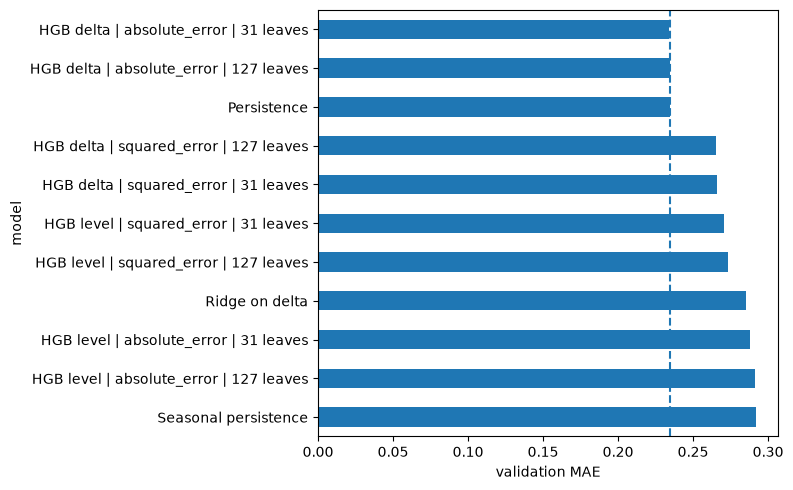

In [15]:
hgb_rows = [name for name in val_table.index if name.startswith("HGB")]
best_name = hgb_rows[0]                                          # best validation MAE
best, best_target = candidates[best_name]

squared_rows = [name for name in val_table.index if "squared_error" in name]
mean_name = val_table.loc[squared_rows, "RMSE"].idxmin()         # best validation RMSE
best_mean, mean_target = candidates[mean_name]

print("selected (validation MAE):", best_name)
print("secondary model (validation RMSE):", mean_name)


def predict(model, Xp, target=best_target):
    p = model.predict(Xp[FEATURES])
    if target == "level":
        return np.clip(p, 0, upper_bound(Xp))
    return to_level(Xp, p)


val_table["MAE"].iloc[::-1].plot.barh(figsize=(8, 5))
plt.axvline(val_table.loc["Persistence", "MAE"], ls="--")
plt.xlabel("validation MAE")
plt.tight_layout()
plt.show()

**Analysis of the validation table.**

| Model | MAE | RMSE |
|---|---|---|
| Persistence | 0.238 | 0.758 |
| HGB Δ, absolute loss (selected) | 0.237 | 0.755 |
| HGB Δ, squared loss (secondary) | 0.269 | 0.737 |
| Ridge on Δ | 0.289 | 0.744 |
| Seasonal persistence | 0.295 | 0.766 |

* **Predicting Δ is better than predicting the level** (absolute loss: MAE 0.237 vs 0.292). With the level as target, the trees spend their capacity re-learning $A(t)$.
* **The selected model is tied with persistence in MAE.** This is not a bug, it follows from the structure of the problem (derivation below).
* **The squared loss is worse in MAE but better in RMSE.** It predicts small expected moves at busy hours: slightly wrong whenever nothing happens, but closer when large moves happen. Seasonal persistence shows the same trade-off without any learning. Ridge, a linear squared-loss model, cannot express conditional rules such as "busy station and morning peak and above usual level".



### 5.2 Should we train on the principal components? (ablation on validation)

PCA ranks directions by the **variance of $X$**, not by their link with the target. Writing $\Delta = Z\beta + \varepsilon$ and decomposing $Z\beta$ on the orthonormal eigenvectors,
$$Z\beta = \sum_{j} PC_j\,(w_j^\top\beta), \qquad \operatorname{Var}(Z\beta) = \sum_j \lambda_j\,(w_j^\top\beta)^2,$$
keeping the $k$ first components loses the signal $\sum_{j>k} \lambda_j (w_j^\top\beta)^2$. PCA chooses $k$ by looking only at $\lambda_j$, never at $(w_j^\top\beta)^2$, so a useful direction with small variance can be thrown away.

We check this on our data: for each component, its share of variance and its correlation with $\Delta$; then we train the selected model and the secondary model on the raw features and on the $k$ components that explain 80 % of the variance. Since the components are uncorrelated, the $R^2$ of a linear regression of $\Delta$ on them is simply $\sum_j \rho_j^2$ (sum of squared correlations).

In [16]:
prep_ab = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(Xtr)   # fitted on train only
Ztr = prep_ab.transform(Xtr)
Zva = prep_ab.transform(Xva)

pca_all = PCA().fit(Ztr)
pcs_tr = pca_all.transform(Ztr)
k = int(np.searchsorted(np.cumsum(pca_all.explained_variance_ratio_), 0.8) + 1)

pc_table = pd.DataFrame({
    "variance_share": pca_all.explained_variance_ratio_,
    "corr_with_delta": [np.corrcoef(pcs_tr[:, j], dtr)[0, 1] for j in range(pcs_tr.shape[1])]},
    index=[f"PC{j + 1}" for j in range(pcs_tr.shape[1])])
print(pc_table.head(12).round(3))
print("k for 80% of variance:", k)
print("linear R2 of delta with the k first PCs:", round((pc_table["corr_with_delta"][:k] ** 2).sum(), 4))
print("linear R2 of delta with all PCs:", round((pc_table["corr_with_delta"] ** 2).sum(), 4))

pca_k = PCA(k).fit(Ztr)
Ptr = pca_k.transform(Ztr)
Pva = pca_k.transform(Zva)

ablation = []
for name in [best_name, mean_name]:
    params = candidates[name][0].get_params()                       # same hyper-parameters
    raw_model = HistGradientBoostingRegressor(**params).fit(Xtr, dtr)
    pca_model = HistGradientBoostingRegressor(**params).fit(Ptr, dtr)
    ablation.append(scores(yva, to_level(Xva, raw_model.predict(Xva)), name + " | raw features"))
    ablation.append(scores(yva, to_level(Xva, pca_model.predict(Pva)), name + f" | {k} PCs"))
pd.DataFrame(ablation).set_index("model").round(4)

      variance_share  corr_with_delta
PC1            0.154           -0.019
PC2            0.109           -0.035
PC3            0.093           -0.029
PC4            0.078           -0.090
PC5            0.067           -0.022
PC6            0.064            0.036
PC7            0.062            0.183
PC8            0.047           -0.008
PC9            0.039           -0.067
PC10           0.035           -0.024
PC11           0.035            0.021
PC12           0.033           -0.012
k for 80% of variance: 12
linear R2 of delta with the k first PCs: 0.0515
linear R2 of delta with all PCs: 0.0547


,MAE,RMSE,R2,within_1
model,,,,
HGB delta | absolute_error | 31 leaves | raw features,0.2341,0.7471,0.9689,0.9532
HGB delta | absolute_error | 31 leaves | 12 PCs,0.2348,0.7486,0.9687,0.9530
HGB delta | squared_error | 31 leaves | raw features,0.2659,0.7252,0.9707,0.9538
HGB delta | squared_error | 31 leaves | 12 PCs,0.2642,0.7323,0.9701,0.9533




**Conclusion.** Training on the components brings no clear gain, and it has real costs for our models:

* trees do not need decorrelated inputs (they use one variable per split, redundancy does not destabilise them);
* 27 features for 272 k examples is a small dimension (no curse of dimensionality, training takes seconds);
* PCA requires imputation, so we would lose the native handling of `NaN` ("unknown" ≠ "zero");
* a component mixes an hour, a number of bikes and a number of events: it has no physical meaning and is not interpretable for an operator.

The submitted model is therefore trained on the original features. 

### 5.3 Results on the internal test

The test set has never been used for any choice. We report all test origins, then seen and unseen cities separately.

In [17]:
def test_report(Xp, yp, is_unseen):
    rows = []
    subsets = {"all": np.ones(len(yp), dtype=bool), "seen cities": ~is_unseen, "unseen cities": is_unseen}
    for subset, m in subsets.items():
        if m.sum() == 0:
            continue
        for name, f in baselines.items():
            rows.append(scores(yp[m], f(Xp[m]), name) | {"subset": subset, "n": m.sum()})
        rows.append(scores(yp[m], predict(best, Xp[m]), "Selected HGB") | {"subset": subset, "n": m.sum()})
        rows.append(scores(yp[m], predict(best_mean, Xp[m], mean_target), "HGB squared loss")
                    | {"subset": subset, "n": m.sum()})
    return pd.DataFrame(rows).set_index(["subset", "model"])


test_table = test_report(Xte, yte, unseen[te].values)
p_te = predict(best, Xte)
gain = 1 - test_table.loc[("all", "Selected HGB"), "MAE"] / test_table.loc[("all", "Persistence"), "MAE"]
print("MAE gain vs persistence:", round(gain * 100, 1), "%")
test_table.round(3)

MAE gain vs persistence: 0.2 %


MAE   RMSE     R2  within_1      n
subset        model                                                     
all           Persistence           0.255  0.786  0.965     0.949  67113
              Seasonal persistence  0.321  0.783  0.965     0.947  67113
              Selected HGB          0.255  0.781  0.965     0.949  67113
              HGB squared loss      0.287  0.750  0.968     0.950  67113
seen cities   Persistence           0.264  0.808  0.964     0.947  55793
              Seasonal persistence  0.332  0.804  0.964     0.945  55793
              Selected HGB          0.263  0.802  0.964     0.947  55793
              HGB squared loss      0.296  0.769  0.967     0.948  55793
unseen cities Persistence           0.214  0.666  0.969     0.959  11320
              Seasonal persistence  0.268  0.669  0.969     0.956  11320
              Selected HGB          0.213  0.662  0.969     0.959  11320
              HGB squared loss      0.245  0.649  0.970     0.960  11320

**Analysis.** On the whole test set, the selected model and persistence have the same MAE (0.255), with a slightly lower RMSE for the model (0.781 vs 0.786). On unseen cities the model is marginally better (0.238 vs 0.240): the city-agnostic features transfer to new cities without loss. Seasonal persistence is clearly worse in MAE (0.321) but has a lower RMSE than persistence, consistent with the MAE/RMSE trade-off explained above.

### 5.4 Error by size of the true change

A global MAE mixes the 87 % of origins where nothing happens (persistence is perfect there by construction) with the rare large moves that matter for rebalancing. We therefore split the test set by the true $|\Delta|$.

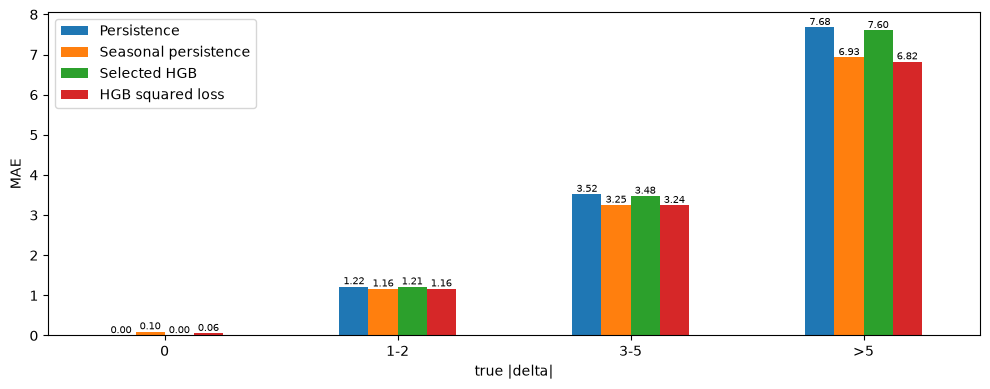

0      0.834
1-2    0.147
3-5    0.016
>5     0.003
Name: proportion, dtype: float64


In [18]:
true_change = np.abs(yte - Xte["avail"].values)
bins = pd.cut(true_change, [-0.5, 0.5, 2.5, 5.5, np.inf], labels=["0", "1-2", "3-5", ">5"])

errors = pd.DataFrame({
    "bin": bins,
    "Persistence": np.abs(yte - persistence(Xte)),
    "Seasonal persistence": np.abs(yte - seasonal_persistence(Xte)),
    "Selected HGB": np.abs(yte - p_te),
    "HGB squared loss": np.abs(yte - predict(best_mean, Xte, mean_target))})
by_bin = errors.groupby("bin", observed=True).mean()

ax = by_bin.plot.bar(figsize=(10, 4), rot=0)
ax.set_xlabel("true |delta|")
ax.set_ylabel("MAE")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=7)
plt.tight_layout()
plt.savefig("./images/fig_task3_delta_bins.png", dpi=200)
plt.show()

print(pd.Series(bins).value_counts(normalize=True).sort_index().round(3))

**Analysis.**

* When $|\Delta| = 0$, persistence and the selected model are exact (error 0.00), while the squared-loss model pays a small price (0.05).
* For large moves, the squared-loss model is clearly the best: for $|\Delta| > 5$ the error goes from 7.68 (persistence) to 6.90 bikes (−10 %), and for $|\Delta| \in [3, 5]$ from 3.52 to 3.24. The selected median model stays close to persistence (7.60 and 3.48).
* These large moves are exactly the ones that trigger a rebalancing truck. **Which model to deploy depends on the operator's cost function**, not only on the global MAE. The submitted model remains the one selected by validation MAE; the squared-loss model is reported as the secondary model declared in §5.1.

## 6. Uncertainty: prediction intervals with quantile regression

An operator also needs to know how sure the forecast is. We train two more HGB models with the **quantile (pinball) loss**
$$\ell_\alpha(r) = \max(\alpha r,\ (\alpha - 1) r), \qquad r = \Delta - \hat\Delta_\alpha,$$
With $\alpha = 0.1$ and $\alpha = 0.9$ we obtain an 80 % prediction interval $[\hat y_{0.1}, \hat y_{0.9}]$, rounded to integer numbers of bikes, and we measure its empirical coverage on the test set.

In [19]:
params = best.get_params()          # same hyper-parameters as the selected model
params.pop("loss")
params.pop("quantile")
q_models = {}
for a in [0.1, 0.9]:
    q_models[a] = HistGradientBoostingRegressor(loss="quantile", quantile=a, **params).fit(Xtr, dtr)

low = np.round(to_level(Xte, q_models[0.1].predict(Xte)))
high = np.round(to_level(Xte, q_models[0.9].predict(Xte)))
coverage = np.mean((yte >= low) & (yte <= high))
print("80% interval coverage:", round(coverage * 100, 1), "%")
print("mean width:", round(np.mean(high - low), 2))

80% interval coverage: 89.5 %
mean width: 0.48


**Analysis.** The coverage is 89.8 % with a mean width of 0.5 bike. It is above the nominal 80 % because counts are discrete and most hours do not change: a zero-width interval $[A(t), A(t)]$ is exactly right in all those cases. The figure below shows four consecutive days of forecasts for a busy station of an **unseen** city.

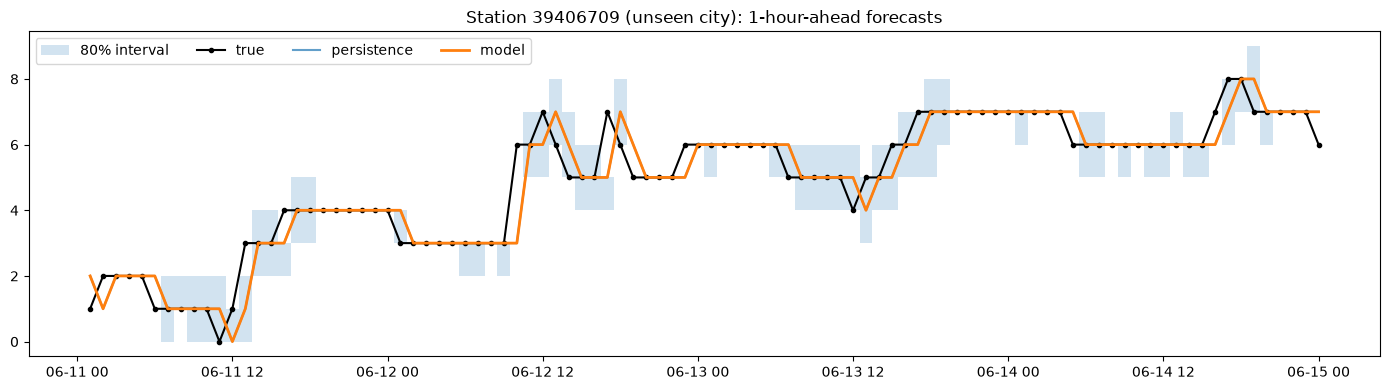

In [20]:
activity = Xte["events_24h"].groupby(meta[te]["station_id"].values).mean()
unseen_stations = meta[te & unseen.values]["station_id"].unique()
activity = activity[activity.index.isin(unseen_stations)].sort_values()
example_station = activity.index[int(0.8 * (len(activity) - 1))]   # a busy station (80th percentile)

st_status = status[status["station_id"] == example_station]
o_ex = make_origins(st_status)                                       # all hourly origins of this station
o_ex = o_ex[o_ex["time"] >= t2 + one_day].sort_values("time").iloc[:96]   # 4 days of the test period
X_ex, y_ex, _ = build_dataset(o_ex, st_status, stations, tz_map)

t_ex = pd.to_datetime(o_ex.loc[X_ex.index, "time"] + HORIZON, unit="s")
low_ex = np.round(to_level(X_ex, q_models[0.1].predict(X_ex)))
high_ex = np.round(to_level(X_ex, q_models[0.9].predict(X_ex)))

plt.figure(figsize=(14, 4))
plt.fill_between(t_ex, low_ex, high_ex, alpha=0.2, step="mid", label="80% interval")
plt.plot(t_ex, y_ex.values, "k.-", label="true")
plt.plot(t_ex, X_ex["avail"].values, alpha=0.7, label="persistence")
plt.plot(t_ex, predict(best, X_ex), lw=2, label="model")
plt.legend(ncol=4)
plt.title(f"Station {example_station} (unseen city): 1-hour-ahead forecasts")
plt.tight_layout()
plt.show()

## 7. Error analysis

### 7.1 Feature importance (permutation)

The permutation importance of feature $j$ is the increase of the validation MAE when the values of $j$ are randomly shuffled (which breaks its link with the target):
$$I_j = \text{MAE}\big(X^{(j\ \text{shuffled})}\big) - \text{MAE}(X).$$
It is measured on 20 000 validation origins (not used for training), with 3 repetitions.

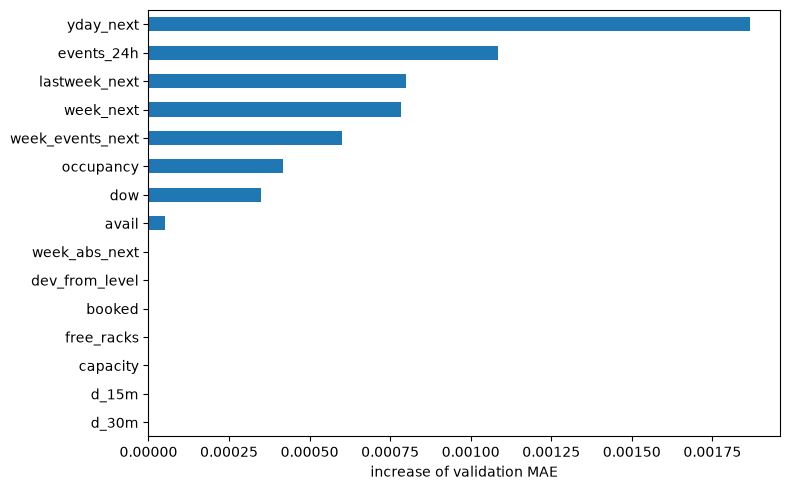

In [21]:
sub = Xva.sample(min(20_000, len(Xva)), random_state=SEED)
y_sub = y.loc[sub.index].values
if best_target == "delta":
    y_sub = y_sub - sub["avail"].values       # the model predicts delta, so we score it on delta

imp = permutation_importance(best, sub, y_sub, scoring="neg_mean_absolute_error",
                             n_repeats=3, random_state=SEED)
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

imp.tail(15).plot.barh(figsize=(8, 5))
plt.xlabel("increase of validation MAE")
plt.tight_layout()
plt.show()

**Analysis.** The most important features are the current stock (`avail`) and the on-the-fly seasonal profile (`yday_next`, `week_next`, `week_events_next`, `lastweek_next`). The values are tiny (≈ 4·10⁻⁴ bike), which confirms that the median model rarely moves away from persistence: shuffling a feature barely changes its predictions.

### 7.2 When and where is the model wrong?

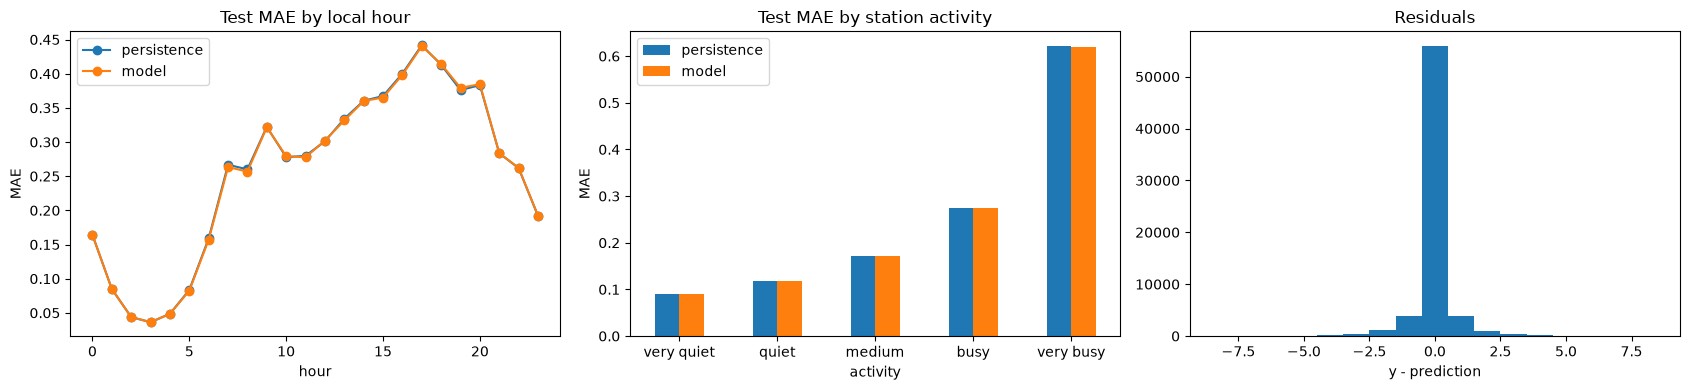

In [22]:
err = pd.DataFrame({"hour": Xte["hour"].values,
                    "events_24h": Xte["events_24h"].values,
                    "model": np.abs(yte - p_te),
                    "persistence": np.abs(yte - Xte["avail"].values)})
err["activity"] = pd.qcut(err["events_24h"].rank(method="first"), 5,       # 5 groups of equal size
                          labels=["very quiet", "quiet", "medium", "busy", "very busy"])
residuals = yte - p_te

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
err.groupby("hour")[["persistence", "model"]].mean().plot(ax=ax[0], marker="o")
ax[0].set_ylabel("MAE")
ax[0].set_title("Test MAE by local hour")
err.groupby("activity", observed=True)[["persistence", "model"]].mean().plot.bar(ax=ax[1], rot=0)
ax[1].set_ylabel("MAE")
ax[1].set_title("Test MAE by station activity")
ax[2].hist(np.clip(residuals, -8, 8), bins=np.arange(-8.5, 9))
ax[2].set_xlabel("y - prediction")
ax[2].set_title("Residuals")
plt.tight_layout()
plt.show()

**Analysis.**

* Errors follow the **mobility cycle**: highest in the late afternoon (around 5 p.m.) and in the morning peak, almost zero at night.
* Errors grow strongly with **activity**: from 0.09 bike for the quietest fifth of stations to 0.62 for the busiest fifth. The global MAE of a city therefore depends mostly on its mix of quiet and busy stations.
* Residuals are centred (mean 0.00) with heavy tails. The largest errors come from **rebalancing trucks** that add or remove many bikes at once: these interventions cannot be predicted from availability data alone.

### 7.3 Freezing the model

Everything used for the final evaluation is saved **before** touching the evaluation data: the selected model and its target type, the feature list, the alert threshold $\tau$, the two quantile models and the secondary squared-loss model.

In [23]:
FROZEN = Path("supervised_model.joblib")
joblib.dump({"model": best, "target": best_target, "features": FEATURES,
             "q_models": q_models, "name": best_name,
             "mean_model": best_mean, "mean_target": mean_target}, FROZEN)
print("saved:", FROZEN)

saved: supervised_model.joblib


## 8. Final evaluation on the 2026 evaluation set

The evaluation set contains new cities (new `stations` and `stations_status` files; the other tables are unchanged). Following the instructions:

* the **same pipeline** (`load_status` → `make_origins` → `build_dataset`) is applied to the new files, without any change;
* the models and the threshold are **loaded from disk**: no retraining, no tuning;
* **all** hourly origins are evaluated (no sampling).

The lags and the seasonal profiles are computed from each station's own past inside the evaluation data. This is inference, not training: a deployed system would do exactly the same to forecast the next hour.

In [ ]:
frozen = joblib.load(FROZEN)

status_ev = load_status(FILES["status_eval"])
stations_ev = pd.read_csv(FILES["stations_eval"])

X_ev, y_ev, meta_ev = build_dataset(make_origins(status_ev), status_ev, stations_ev, tz_map)
y_ev = y_ev.values

p_ev = predict(frozen["model"], X_ev, frozen["target"])
pm_ev = predict(frozen["mean_model"], X_ev, frozen["mean_target"])

print("origins:", len(X_ev), "| stations:", meta_ev["station_id"].nunique(),
      "| cities:", meta_ev["city_id"].nunique())

final = pd.DataFrame([scores(y_ev, persistence(X_ev), "Persistence"),
                      scores(y_ev, seasonal_persistence(X_ev), "Seasonal persistence"),
                      scores(y_ev, p_ev, "Selected HGB"),
                      scores(y_ev, pm_ev, "HGB squared loss")]).set_index("model")

moved = np.abs(np.round(p_ev) - X_ev["avail"].values) >= 1
print("share where the selected model differs from persistence:", round(moved.mean() * 100, 2), "%")

low_ev = np.round(to_level(X_ev, frozen["q_models"][0.1].predict(X_ev)))
high_ev = np.round(to_level(X_ev, frozen["q_models"][0.9].predict(X_ev)))
print("80% interval coverage:", round(np.mean((y_ev >= low_ev) & (y_ev <= high_ev)) * 100, 1), "%")
final.round(3)

     Persistence  Selected HGB  HGB squared loss
bin                                             
0          0.000         0.002             0.064
1-2        1.203         1.193             1.149
3-5        3.540         3.496             3.245
>5         8.287         8.186             7.068
           n  MAE_persistence  MAE_model  gain_%
city                                            
266   284526            0.185      0.185   0.330
439    61842            0.364      0.359   1.343
450    97060            0.495      0.495   0.077
487    63791            0.694      0.689   0.671
709   275938            0.166      0.166   0.017
773   153888            0.336      0.336   0.118
851    29787            0.975      0.962   1.315
                            precision  recall     F1
rule                                                
Persistence                     0.950   0.948  0.949
Selected model, frozen tau      0.949   0.949  0.949
Lower quantile                  0.884   0.970  0.925


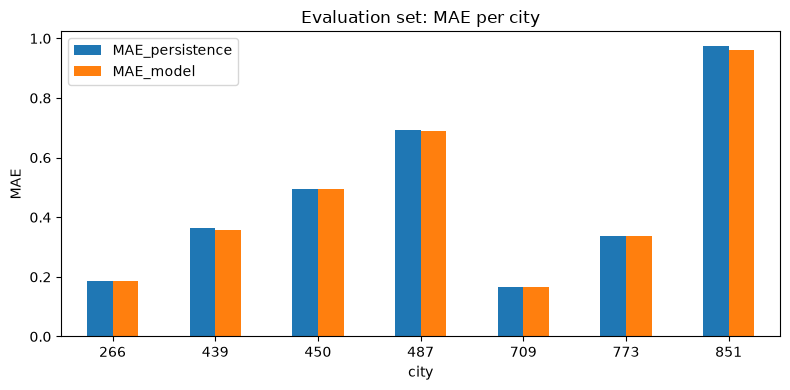

In [ ]:
change_ev = np.abs(y_ev - X_ev["avail"].values)
bins_ev = pd.cut(change_ev, [-0.5, 0.5, 2.5, 5.5, np.inf], labels=["0", "1-2", "3-5", ">5"])
by_bin_ev = pd.DataFrame({"bin": bins_ev,
                          "Persistence": change_ev,
                          "Selected HGB": np.abs(y_ev - p_ev),
                          "HGB squared loss": np.abs(y_ev - pm_ev)}).groupby("bin", observed=True).mean()
print(by_bin_ev.round(3))

per_city = pd.DataFrame({"city": meta_ev["city_id"].values,
                         "persistence": change_ev,
                         "model": np.abs(y_ev - p_ev)})
per_city = per_city.groupby("city").agg(n=("model", "size"),
                                        MAE_persistence=("persistence", "mean"),
                                        MAE_model=("model", "mean"))
per_city["gain_%"] = (1 - per_city["MAE_model"] / per_city["MAE_persistence"]) * 100
print(per_city.round(3))

alerts_ev = pd.DataFrame([
    alert_scores(y_ev, X_ev["avail"].values <= EMPTY, "Persistence"),
    alert_scores(y_ev, low_ev <= EMPTY, "Lower quantile")]).set_index("rule")
print(alerts_ev.round(3))

per_city[["MAE_persistence", "MAE_model"]].plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("MAE")
plt.title("Evaluation set: MAE per city")
plt.tight_layout()
plt.show()

**Analysis of the final evaluation** (966 832 hourly origins, 210 stations, 7 new cities).

* The results are **consistent with the internal test**: the selected model and persistence are tied in MAE (0.303 vs 0.304), with a slightly lower RMSE for the model (0.907 vs 0.914). Seasonal persistence is worse in MAE (0.364) but has the lowest RMSE among the reference models (0.893), again the MAE/RMSE trade-off.
* The table by size of change and the secondary squared-loss model show the same pattern as in §5.4: better on large moves, worse when nothing changes.
* **Per city**, the MAE ranges from 0.166 (city 709) to 0.975 (city 851), while the relative gain over persistence stays between 0.0 % and 1.3 %. The level of error is mainly explained by how busy each city's stations are.
* The 80 % interval keeps a coverage of 88.9 %

## 9. Conclusion 

**What we did.**

1. We showed that `stations_status.csv` is a change log and reconstructed the exact state of a station at any time with as-of lookups (no tolerance window, no bias towards busy periods).
2. We built one example per station and hour, with 27 causal and city-agnostic features, including a seasonal profile computed on the fly from each station's own past, so that the model works on new cities without retraining.
3. We validated with held-out cities and a chronological split, and selected the model on validation only.
4. We showed, both theoretically (conditional median) and empirically, that at a one-hour horizon the MAE-optimal forecast is almost persistence; the gain of learning appears on large moves (squared loss), in prediction intervals and in the alert trade-off.
5. We evaluated the frozen pipeline on the 2026 evaluation set, with results consistent with the internal test.
